In [1]:
from pathlib import Path
import sys

from IPython.display import display


def find_project_root(start_path: Path) -> Path:
    # Resolve imports from either the repository root or notebooks directory.
    for path in [start_path, *start_path.parents]:
        if (path / "src").is_dir() and (path / "requirements.txt").is_file():
            return path
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import matplotlib.pyplot as plt

from src.analysis.presentation import format_analysis_table
from src.analysis.orders import build_order_analysis_view
from src.analysis.summary import summarize_delivery_by_slot
from src.analysis.statistics import test_slot_association
from src.analysis.slot_comparisons import (
    COMPARISON_SLOTS, compare_approval_slot_groups, summarize_slot_group_months,
)

from src.analysis.plots import (
    build_temporal_profiles, plot_slot_counts, plot_rate_profile,
    plot_hour_weekday_heatmap, plot_delay_distribution,
)
from src.analysis.route_slots import build_state_pair_orders, summarize_state_pair_slots
from src.analysis.route_stages import (
    compare_route_delivery_stages, summarize_afternoon_route_evidence, summarize_route_slot_evidence,
    summarize_stage_slots,
)
from src.data_loader import load_data
from src.paths import PROCESSED_DIR

from src.analysis.investigation import (
    summarize_time_periods, compare_cleaning_cohorts, investigate_delivery_stages,
    classify_order_routes, summarize_routes, summarize_focus_routes, build_focus_cohort, summarize_destination_states,
    summarize_state_pairs, summarize_focus_time, summarize_focus_comparisons,
)
from src.analysis.investigation_plots import (
    plot_monthly_slot_rates, plot_matched_years, plot_stage_comparison, plot_promised_windows,
    plot_slot_group_months, plot_slot_group_comparison, plot_focus_routes, plot_route_slot_rates, plot_route_transit_time, plot_destination_states, plot_state_pairs,
    plot_focus_months, plot_focus_approval_time,
    plot_state_pair_slots, plot_state_pair_months,
    plot_route_period_medians,
    plot_route_period_slot_rates,
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed input: {PROCESSED_DIR}")


Project root: C:\Users\trang\PycharmProjects\Intro-to-DataScience-Project
Processed input: C:\Users\trang\PycharmProjects\Intro-to-DataScience-Project\data\processed


In [3]:
cleaned_items = load_data("cleaned_order_items", stage="processed")

Loaded PARQUET from 'C:\Users\trang\PycharmProjects\Intro-to-DataScience-Project\data\processed\cleaned_order_items.parquet'.


In [4]:
import pandas as pd

items = cleaned_items.copy()

# Convert timestamp columns to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    items[col] = pd.to_datetime(items[col], errors="raise")

# General information
print("Total item records:", len(items))
print("Unique orders:", items["order_id"].nunique())
print("Duplicate order-item keys:",
      items.duplicated(["order_id", "order_item_id"]).sum())

print("\nOrder status:")
print(items["order_status"].value_counts())

Total item records: 108571
Unique orders: 95075
Duplicate order-item keys: 0

Order status:
order_status
delivered    108571
Name: count, dtype: int64[pyarrow]


In [5]:
order_fields = [
    "customer_id",
    "order_status",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "customer_city",
    "customer_state",
    "customer_zip_code_prefix"
]

# Number of different values within each order
consistency = (
    items.groupby("order_id")[order_fields]
    .nunique(dropna=False)
)

conflicts = consistency.gt(1)

print("Conflicting orders by field:")
print(conflicts.sum())

assert not conflicts.to_numpy().any(), \
    "Found inconsistent order-level information!"

Conflicting orders by field:
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_city                    0
customer_state                   0
customer_zip_code_prefix         0
dtype: int64


In [6]:
# Calculate the volume of each item
items["item_volume_cm3"] = (
    items["product_length_cm"]
    * items["product_height_cm"]
    * items["product_width_cm"]
)

display(items[[
    "order_id",
    "product_id",
    "product_weight_g",
    "item_volume_cm3"
]].head())

,order_id,product_id,product_weight_g,item_volume_cm3
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,650.0,3528.0
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,30000.0,60000.0
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,3050.0,14157.0
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,200.0,2400.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,3750.0,42000.0


In [7]:
orders_df = (
    items.groupby("order_id", as_index=False)
    .agg(
        # Order-level attributes
        customer_id=("customer_id", "first"),
        order_status=("order_status", "first"),
        customer_city=("customer_city", "first"),
        customer_state=("customer_state", "first"),
        customer_zip_code_prefix=(
            "customer_zip_code_prefix", "first"
        ),

        # Timestamps
        order_purchase_timestamp=(
            "order_purchase_timestamp", "first"
        ),
        order_approved_at=("order_approved_at", "first"),
        order_delivered_customer_date=(
            "order_delivered_customer_date", "first"
        ),
        order_estimated_delivery_date=(
            "order_estimated_delivery_date", "first"
        ),

        # Order characteristics
        item_count=("order_item_id", "size"),
        n_products=("product_id", "nunique"),
        n_sellers=("seller_id", "nunique"),
        n_seller_states=("seller_state", "nunique"),
        n_categories=("product_category_name", "nunique"),

        # Financial attributes
        order_value=("price", "sum"),
        freight_total=("freight_value", "sum"),

        # Physical attributes
        total_weight_g=(
            "product_weight_g",
            lambda s: s.sum(min_count=1)
        ),
        total_volume_cm3=(
            "item_volume_cm3",
            lambda s: s.sum(min_count=1)
        )
    )
)

print("Shape:", orders_df.shape)
display(orders_df.head())

Shape: (95075, 19)


,order_id,customer_id,order_status,customer_city,customer_state,customer_zip_code_prefix,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,item_count,n_products,n_sellers,n_seller_states,n_categories,order_value,freight_total,total_weight_g,total_volume_cm3
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,campos dos goytacazes,RJ,28013,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29,1,1,1,1,1,58.90,13.29,650.0,3528.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,santa fe do sul,SP,15775,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15,1,1,1,1,1,239.90,19.93,30000.0,60000.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,para de minas,MG,35661,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05,1,1,1,1,1,199.00,17.87,3050.0,14157.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,atibaia,SP,12952,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20,1,1,1,1,1,12.99,12.79,200.0,2400.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,varzea paulista,SP,13226,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,1,1,1,1,1,199.90,18.14,3750.0,42000.0


In [8]:
actual = (
    orders_df["order_delivered_customer_date"]
    .dt.normalize()
)

estimated = (
    orders_df["order_estimated_delivery_date"]
    .dt.normalize()
)

# Ensure all delivery outcomes are known
assert actual.notna().all()
assert estimated.notna().all()

# Signed difference in calendar days
orders_df["signed_delay_days"] = (
    actual - estimated
).dt.days

# Binary target
orders_df["is_late"] = (
    orders_df["signed_delay_days"] > 0
).astype("int8")

# Nonnegative delay duration
orders_df["delay_days"] = (
    orders_df["signed_delay_days"].clip(lower=0)
)

display(orders_df[[
    "order_id",
    "order_estimated_delivery_date",
    "order_delivered_customer_date",
    "signed_delay_days",
    "delay_days",
    "is_late"
]].head(10))

,order_id,order_estimated_delivery_date,order_delivered_customer_date,signed_delay_days,delay_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-29,2017-09-20 23:43:48,-9,0,0
1,00018f77f2f0320c557190d7a144bdd3,2017-05-15,2017-05-12 16:04:24,-3,0,0
2,000229ec398224ef6ca0657da4fc703e,2018-02-05,2018-01-22 13:19:16,-14,0,0
3,00024acbcdf0a6daa1e931b038114c75,2018-08-20,2018-08-14 13:32:39,-6,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-03-17,2017-03-01 16:42:31,-16,0,0
5,00048cc3ae777c65dbb7d2a0634bc1ea,2017-06-06,2017-05-22 13:44:35,-15,0,0
6,00054e8431b9d7675808bcb819fb4a32,2018-01-04,2017-12-18 22:03:38,-17,0,0
7,0005a1a1728c9d785b8e2b08b904576c,2018-03-29,2018-03-29 18:17:31,0,0,0
8,0005f50442cb953dcd1d21e1fb923495,2018-07-23,2018-07-04 17:28:31,-19,0,0
9,00061f2a7bc09da83e415a52dc8a4af1,2018-04-09,2018-03-29 00:04:19,-11,0,0


In [9]:
# 1. Ensure one row per order
assert orders_df["order_id"].is_unique

# 2. Preserve all input orders
assert len(orders_df) == items["order_id"].nunique()

# 3. Preserve total item count
assert orders_df["item_count"].sum() == len(items)

# 4. Preserve monetary totals
import numpy as np

assert np.isclose(
    orders_df["order_value"].sum(),
    items["price"].sum()
)

assert np.isclose(
    orders_df["freight_total"].sum(),
    items["freight_value"].sum()
)

# 5. Inspect target distribution
target_summary = (
    orders_df["is_late"]
    .value_counts()
    .sort_index()
    .rename_axis("is_late")
    .reset_index(name="orders")
)

target_summary["percentage"] = (
    target_summary["orders"]
    / len(orders_df)
    * 100
).round(2)

display(target_summary)

print("Total orders:", len(orders_df))
print("Total features/columns:", orders_df.shape[1])
print("Missing values:")
display(orders_df.isna().sum().sort_values(ascending=False))

,is_late,orders,percentage
0,0,88566,93.15
1,1,6509,6.85


Total orders: 95075
Total features/columns: 22
Missing values:


total_weight_g                   16
total_volume_cm3                 16
order_status                      0
customer_city                     0
order_id                          0
customer_id                       0
customer_zip_code_prefix          0
customer_state                    0
order_purchase_timestamp          0
order_approved_at                 0
item_count                        0
n_products                        0
order_delivered_customer_date     0
order_estimated_delivery_date     0
n_seller_states                   0
n_sellers                         0
order_value                       0
n_categories                      0
freight_total                     0
signed_delay_days                 0
is_late                           0
delay_days                        0
dtype: int64

In [10]:
eda_orders, eda_diagnostics = build_order_analysis_view(
    cleaned_items
)

comparison = orders_df[["order_id", "is_late"]].merge(
    eda_orders[["order_id", "is_late"]],
    on="order_id",
    how="outer",
    suffixes=("_model", "_eda"),
    indicator=True,
    validate="one_to_one"
)

print("Order matching:")
print(comparison["_merge"].value_counts())

matched = comparison["_merge"].eq("both")

mismatches = comparison.loc[
    matched &
    comparison["is_late_model"].ne(
        comparison["is_late_eda"]
    )
]

print("Target mismatches:", len(mismatches))
display(mismatches.head())

Order matching:
_merge
both          95075
left_only         0
right_only        0
Name: count, dtype: int64
Target mismatches: 0


,order_id,is_late_model,is_late_eda,_merge


In [11]:

import numpy as np
import pandas as pd

# Start from validated order-level data
model_df = orders_df.copy()

assert model_df["order_id"].is_unique

# Representative category, only if the order has one category
first_category = (
    items.dropna(subset=["product_category_name"])
    .drop_duplicates("order_id")
    .set_index("order_id")["product_category_name"]
)

model_df["product_category_group"] = (
    model_df["order_id"].map(first_category).astype("object")
)

model_df.loc[
    model_df["n_categories"] == 0,
    "product_category_group"
] = "__UNKNOWN__"

model_df.loc[
    model_df["n_categories"] > 1,
    "product_category_group"
] = "__MULTIPLE__"

# Representative seller state
first_seller_state = (
    items.dropna(subset=["seller_state"])
    .drop_duplicates("order_id")
    .set_index("order_id")["seller_state"]
)

model_df["seller_state_group"] = (
    model_df["order_id"].map(first_seller_state).astype("object")
)

model_df.loc[
    model_df["n_seller_states"] == 0,
    "seller_state_group"
] = "__UNKNOWN__"

model_df.loc[
    model_df["n_seller_states"] > 1,
    "seller_state_group"
] = "__MULTIPLE__"

# Geographic relationship at item level
routes = items[
    ["order_id", "seller_state", "customer_state"]
].copy()

valid_route = (
    routes["seller_state"].notna()
    & routes["customer_state"].notna()
)

routes["interstate_item"] = (
    routes["seller_state"].ne(routes["customer_state"])
    .where(valid_route)
    .astype("Float64")
)

route_features = (
    routes.groupby("order_id", as_index=False)
    .agg(interstate_item_share=("interstate_item", "mean"))
)

model_df = model_df.merge(
    route_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

display(model_df[[
    "order_id",
    "customer_state",
    "seller_state_group",
    "product_category_group",
    "interstate_item_share"
]].head(10))


,order_id,customer_state,seller_state_group,product_category_group,interstate_item_share
0,00010242fe8c5a6d1ba2dd792cb16214,RJ,SP,cool_stuff,1.0
1,00018f77f2f0320c557190d7a144bdd3,SP,SP,pet_shop,0.0
2,000229ec398224ef6ca0657da4fc703e,MG,MG,moveis_decoracao,0.0
3,00024acbcdf0a6daa1e931b038114c75,SP,SP,perfumaria,0.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,SP,PR,ferramentas_jardim,1.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,MG,SP,utilidades_domesticas,1.0
6,00054e8431b9d7675808bcb819fb4a32,SP,SP,telefonia,0.0
7,0005a1a1728c9d785b8e2b08b904576c,SP,SP,beleza_saude,0.0
8,0005f50442cb953dcd1d21e1fb923495,SP,SP,livros_tecnicos,0.0
9,00061f2a7bc09da83e415a52dc8a4af1,SP,SP,beleza_saude,0.0


In [12]:

purchase = pd.to_datetime(
    model_df["order_purchase_timestamp"]
)

approval = pd.to_datetime(
    model_df["order_approved_at"]
)

estimated = pd.to_datetime(
    model_df["order_estimated_delivery_date"]
)

# Calendar features
model_df["approval_hour"] = approval.dt.hour
model_df["approval_weekday"] = approval.dt.day_name()
model_df["approval_month"] = approval.dt.month_name()

# Approval slots, consistent with EDA
model_df["approval_slot"] = pd.cut(
    model_df["approval_hour"],
    bins=[0, 6, 12, 18, 24],
    labels=[
        "00-06", "06-12", "12-18", "18-24"
    ],
    right=False
)

# Cyclical hour representation
model_df["approval_hour_sin"] = np.sin(
    2 * np.pi * model_df["approval_hour"] / 24
)

model_df["approval_hour_cos"] = np.cos(
    2 * np.pi * model_df["approval_hour"] / 24
)

# Hours from purchase to approval
model_df["approval_delay_hours"] = (
    (approval - purchase).dt.total_seconds() / 3600
)

# Invalid approval sequence should not be treated
# as a valid negative approval duration
negative_approval = model_df["approval_delay_hours"] < 0

print("Negative approval durations:",
      negative_approval.sum())

model_df.loc[
    negative_approval, "approval_delay_hours"
] = np.nan

# Calendar days between approval and promised delivery
model_df["promised_days_from_approval"] = (
    estimated.dt.normalize() - approval.dt.normalize()
).dt.days

print(
    "Negative promised days:",
    (model_df["promised_days_from_approval"] < 0).sum()
)

display(model_df[[
    "approval_hour",
    "approval_weekday",
    "approval_slot",
    "approval_delay_hours",
    "promised_days_from_approval"
]].head(10))


Negative approval durations: 0
Negative promised days: 1


,approval_hour,approval_weekday,approval_slot,approval_delay_hours,promised_days_from_approval
0,9,Wednesday,06-12,0.775833,16
1,11,Wednesday,06-12,0.201944,19
2,14,Sunday,12-18,0.249722,22
3,10,Wednesday,06-12,0.161944,12
4,14,Saturday,12-18,0.206111,41
5,3,Wednesday,00-06,30.214722,20
6,12,Sunday,12-18,0.278611,25
7,18,Tuesday,18-24,23.913333,9
8,14,Monday,12-18,0.188056,21
9,22,Saturday,18-24,0.199722,16


In [13]:

# Average item price
model_df["avg_item_price"] = (
    model_df["order_value"] / model_df["item_count"]
)

# Fraction of the total payment allocated to freight
total_payment = (
    model_df["order_value"] + model_df["freight_total"]
)

model_df["freight_share"] = (
    model_df["freight_total"]
    / total_payment.replace(0, np.nan)
)

# Binary indicators
model_df["is_multi_seller"] = (
    model_df["n_sellers"] > 1
).astype("int8")

model_df["is_multi_item"] = (
    model_df["item_count"] > 1
).astype("int8")

# Coverage of physical product information
item_groups = items.groupby("order_id")

item_counts = item_groups.size()

weight_coverage = (
    item_groups["product_weight_g"].count() / item_counts
)

volume_coverage = (
    item_groups["item_volume_cm3"].count() / item_counts
)

model_df["weight_observed_share"] = (
    model_df["order_id"].map(weight_coverage)
)

model_df["volume_observed_share"] = (
    model_df["order_id"].map(volume_coverage)
)

display(model_df[[
    "order_value",
    "freight_total",
    "avg_item_price",
    "freight_share",
    "is_multi_seller",
    "weight_observed_share"
]].head(10))


,order_value,freight_total,avg_item_price,freight_share,is_multi_seller,weight_observed_share
0,58.90,13.29,58.90,0.184098,0,1.0
1,239.90,19.93,239.90,0.076704,0,1.0
2,199.00,17.87,199.00,0.082400,0,1.0
3,12.99,12.79,12.99,0.496121,0,1.0
4,199.90,18.14,199.90,0.083196,0,1.0
5,21.90,12.69,21.90,0.366869,0,1.0
6,19.90,11.85,19.90,0.373228,0,1.0
7,145.95,11.65,145.95,0.073921,0,1.0
8,53.99,11.40,53.99,0.174339,0,1.0
9,59.99,8.88,59.99,0.128939,0,1.0


In [14]:

numerical_features = [
    # Order characteristics
    "item_count",
    "n_products",
    "n_sellers",
    "n_seller_states",
    "n_categories",

    # Financial
    "order_value",
    "freight_total",
    "avg_item_price",
    "freight_share",

    # Product physical properties
    "total_weight_g",
    "total_volume_cm3",
    "weight_observed_share",
    "volume_observed_share",

    # Temporal
    "approval_hour",
    "approval_hour_sin",
    "approval_hour_cos",
    "approval_delay_hours",
    "promised_days_from_approval",

    # Order / geographic indicators
    "is_multi_seller",
    "is_multi_item",
    "interstate_item_share"
]

categorical_features = [
    "customer_state",
    "seller_state_group",
    "product_category_group",
    "approval_slot",
    "approval_weekday",
    "approval_month"
]

feature_columns = numerical_features + categorical_features

# Ensure all selected features exist
missing_features = [
    col for col in feature_columns
    if col not in model_df.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

# Construct feature matrix and target
X = model_df[feature_columns].copy()
y = model_df["is_late"].copy()

# Metadata for chronological splitting in Section 3
split_metadata = model_df[[
    "order_id",
    "order_approved_at"
]].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


X shape: (95075, 27)
y shape: (95075,)
Numerical features: 21
Categorical features: 6


In [15]:

# Columns forbidden from model input
leakage_columns = {
    "order_id",
    "customer_id",
    "order_status",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_limit_date",
    "signed_delay_days",
    "delay_days",
    "is_late"
}

# Verify no prohibited columns enter X
assert leakage_columns.isdisjoint(X.columns), (
    "Potential leakage detected in X!"
)

# Check shapes and target integrity
assert len(X) == len(y) == len(split_metadata)
assert set(y.dropna().unique()).issubset({0, 1})
assert y.notna().all()
assert model_df["order_id"].is_unique

# Check numerical infinities
numeric_values = X[numerical_features].to_numpy(
    dtype=float, na_value=np.nan
)

print("Infinite values:",
      np.isinf(numeric_values).sum())

assert not np.isinf(numeric_values).any()

# Missing values
missing_report = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_pct": X.isna().mean() * 100,
    "unique_values": X.nunique(dropna=True)
}).sort_values("missing_count", ascending=False)

display(missing_report)

# Target distribution
print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nFinal feature matrix:")
print(X.shape)


Infinite values: 0


,missing_count,missing_pct,unique_values
total_weight_g,16,0.016829,2837
total_volume_cm3,16,0.016829,6195
item_count,0,0.000000,17
n_sellers,0,0.000000,5
n_products,0,0.000000,8
n_seller_states,0,0.000000,3
n_categories,0,0.000000,4
freight_total,0,0.000000,7827
order_value,0,0.000000,7573
freight_share,0,0.000000,43146



Target distribution:
is_late
0    88566
1     6509
Name: count, dtype: int64

Target percentages:
is_late
0    93.15
1     6.85
Name: proportion, dtype: float64

Final feature matrix:
(95075, 27)


In [16]:
# Check approval date range
approval_dates = pd.to_datetime(
    split_metadata["order_approved_at"]
)

print("Earliest approval:", approval_dates.min())
print("Latest approval:", approval_dates.max())
print("Missing approval dates:", approval_dates.isna().sum())

# Monthly distribution of orders and late deliveries
temporal_df = pd.DataFrame({
    "approval_date": approval_dates,
    "is_late": y
})

temporal_df["approval_month"] = (
    temporal_df["approval_date"].dt.to_period("M")
)

monthly_summary = (
    temporal_df.groupby("approval_month")
    .agg(
        total_orders=("is_late", "size"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
    .reset_index()
)

monthly_summary["late_rate"] *= 100

display(monthly_summary)

Earliest approval: 2016-09-15 12:16:38
Latest approval: 2018-08-29 15:10:26
Missing approval dates: 0


,approval_month,total_orders,late_orders,late_rate
0,2016-09,1,1,100.000000
1,2016-10,261,2,0.766284
2,2016-12,1,0,0.000000
3,2017-01,714,21,2.941176
4,2017-02,1636,46,2.811736
5,2017-03,2552,118,4.623824
6,2017-04,2254,148,6.566105
7,2017-05,3531,108,3.058624
8,2017-06,3140,94,2.993631
9,2017-07,3814,107,2.805454


In [17]:
# Create chronological order
timeline = model_df[[
    "order_id",
    "order_approved_at",
    "order_delivered_customer_date",
    "is_late"
]].copy()

timeline["order_approved_at"] = pd.to_datetime(
    timeline["order_approved_at"]
)

timeline["order_delivered_customer_date"] = pd.to_datetime(
    timeline["order_delivered_customer_date"]
)

timeline = (
    timeline.sort_values(
        ["order_approved_at", "order_id"]
    )
    .reset_index(drop=True)
)

# Preliminary 70/15/15 cutoffs
n = len(timeline)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

val_start_date = timeline.loc[
    train_end, "order_approved_at"
]

test_start_date = timeline.loc[
    val_end, "order_approved_at"
]

# Labels not yet observable at each cutoff
train_pending = (
    timeline.iloc[:train_end][
        "order_delivered_customer_date"
    ] >= val_start_date
).sum()

val_pending = (
    timeline.iloc[train_end:val_end][
        "order_delivered_customer_date"
    ] >= test_start_date
).sum()

print("Validation starts:", val_start_date)
print("Test starts:", test_start_date)

print("\nTrain labels unavailable at validation start:",
      train_pending)

print("Validation labels unavailable at test start:",
      val_pending)

Validation starts: 2018-04-12 08:32:19
Test starts: 2018-06-19 04:16:58

Train labels unavailable at validation start: 3077
Validation labels unavailable at test start: 2020


In [18]:
approval = pd.to_datetime(model_df["order_approved_at"])
delivered = pd.to_datetime(
    model_df["order_delivered_customer_date"]
)

# Calendar cutoffs
train_end = pd.Timestamp("2018-01-01")
val_start = pd.Timestamp("2018-03-01")
val_end = pd.Timestamp("2018-05-01")
test_start = pd.Timestamp("2018-07-01")
test_end = pd.Timestamp("2018-09-01")

# Candidate cohorts by approval time
train_cohort = approval < train_end

val_cohort = (
    (approval >= val_start)
    & (approval < val_end)
)

test_cohort = (
    (approval >= test_start)
    & (approval < test_end)
)

# Outcome availability at each model decision point
train_known = delivered.notna() & (delivered < val_start)
val_known = delivered.notna() & (delivered < test_start)

diagnostics = pd.DataFrame({
    "cohort": ["Train", "Validation", "Test"],
    "total_orders": [
        train_cohort.sum(),
        val_cohort.sum(),
        test_cohort.sum()
    ],
    "labels_unavailable_at_cutoff": [
        (train_cohort & ~train_known).sum(),
        (val_cohort & ~val_known).sum(),
        np.nan
    ],
    "late_orders_full_cohort": [
        y.loc[train_cohort].sum(),
        y.loc[val_cohort].sum(),
        y.loc[test_cohort].sum()
    ]
})

display(diagnostics)

,cohort,total_orders,labels_unavailable_at_cutoff,late_orders_full_cohort
0,Train,43514,19.0,2449
1,Validation,13331,4.0,1661
2,Test,11868,NaN,593


In [19]:
# Use only labels observable at each cutoff
train_mask = train_cohort & train_known
val_mask = val_cohort & val_known
test_mask = test_cohort

# Ensure disjoint cohorts
assert not (train_mask & val_mask).any()
assert not (train_mask & test_mask).any()
assert not (val_mask & test_mask).any()

# Create feature matrices
X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

# Create target vectors
y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()
y_test = y.loc[test_mask].copy()

# Verify data alignment
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

# Check both classes exist in each split
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    assert target.nunique() == 2, (
        f"{name} does not contain both classes"
    )

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (43495, 27)
Validation: (13327, 27)
Test: (11868, 27)


In [20]:
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Orders": [
        len(y_train), len(y_val), len(y_test)
    ],
    "Late Orders": [
        y_train.sum(), y_val.sum(), y_test.sum()
    ],
    "Late Rate (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

,Dataset,Orders,Late Orders,Late Rate (%)
0,Train,43495,2430,5.59
1,Validation,13327,1657,12.43
2,Test,11868,593,5.00


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Ensure numerical features have compatible dtypes
for subset in [X_train, X_val, X_test]:
    subset[numerical_features] = (
        subset[numerical_features].astype("float64")
    )

    subset[categorical_features] = (
        subset[categorical_features].astype("object")
    )

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(feature_columns))

Numerical features: 21
Categorical features: 6
Total features: 27


In [22]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=0.3
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [23]:
# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

# Retrieve transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

display(pd.DataFrame({
    "feature_name": feature_names
}).head(30))

Train: (43495, 166)
Validation: (13327, 166)
Test: (11868, 166)
Total transformed features: 166


,feature_name
0,num__item_count
1,num__n_products
2,num__n_sellers
3,num__n_seller_states
4,num__n_categories
5,num__order_value
6,num__freight_total
7,num__avg_item_price
8,num__freight_share
9,num__total_weight_g


In [24]:
from scipy import sparse

def validate_transformed_data(matrix, name):
    # Sparse matrices store only nonzero elements
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)

    missing_count = np.isnan(values).sum()
    infinite_count = np.isinf(values).sum()

    print(f"\n{name}")
    print("Shape:", matrix.shape)
    print("Missing:", missing_count)
    print("Infinite:", infinite_count)
    print("Sparse:", sparse.issparse(matrix))

    assert missing_count == 0
    assert infinite_count == 0


validate_transformed_data(X_train_processed, "Train")
validate_transformed_data(X_val_processed, "Validation")
validate_transformed_data(X_test_processed, "Test")

# All datasets must have identical transformed feature dimensions
assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
)

print("\nAll preprocessing checks passed.")


Train
Shape: (43495, 166)
Missing: 0
Infinite: 0
Sparse: True

Validation
Shape: (13327, 166)
Missing: 0
Infinite: 0
Sparse: True

Test
Shape: (11868, 166)
Missing: 0
Infinite: 0
Sparse: True

All preprocessing checks passed.


In [25]:

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=42
    ),

    "Logistic Regression Balanced": LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest Balanced": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    print(f"Training: {name}")

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(f"Completed: {name}\n")


Training: Dummy
Completed: Dummy

Training: Logistic Regression
Completed: Logistic Regression

Training: Logistic Regression Balanced
Completed: Logistic Regression Balanced

Training: Random Forest Balanced
Completed: Random Forest Balanced



In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

evaluation_results = []
validation_probs = {}

for name, model in trained_models.items():

    # Probability of late delivery (class 1)
    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    validation_probs[name] = y_prob

    # Default classification threshold
    y_pred = (y_prob >= 0.5).astype(int)

    evaluation_results.append({
        "Model": name,
        "PR-AUC (AP)": average_precision_score(
            y_val, y_prob
        ),
        "ROC-AUC": roc_auc_score(
            y_val, y_prob
        ),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_val, y_pred
        )
    })

results_df = pd.DataFrame(evaluation_results)

results_df = (
    results_df
    .sort_values("PR-AUC (AP)", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))


,Model,PR-AUC (AP),ROC-AUC,Precision,Recall,F1,Accuracy
0,Logistic Regression,0.2128,0.6377,0.2500,0.0006,0.0012,0.8755
1,Logistic Regression Balanced,0.1927,0.6138,0.1667,0.5468,0.2555,0.6037
2,Random Forest Balanced,0.1860,0.6013,0.2000,0.0006,0.0012,0.8754
3,Dummy,0.1243,0.5000,0.0000,0.0000,0.0000,0.8757


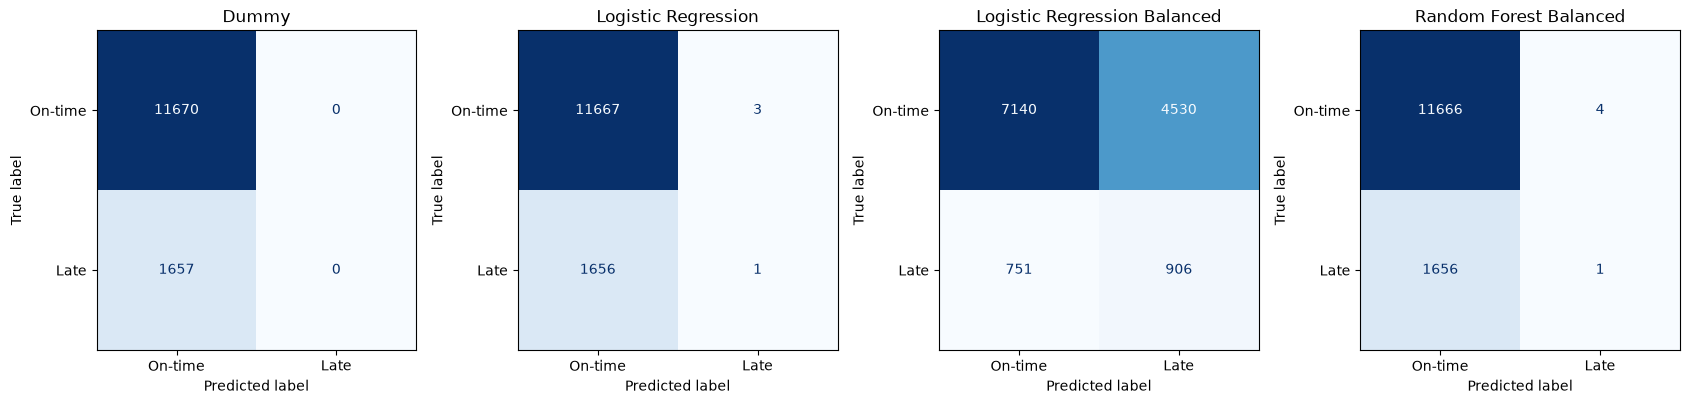

In [27]:

import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1, len(trained_models),
    figsize=(17, 4)
)

for ax, (name, model) in zip(
    axes, trained_models.items()
):
    y_pred = model.predict(X_val_processed)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        labels=[0, 1],
        display_labels=["On-time", "Late"],
        ax=ax,
        colorbar=False,
        cmap="Blues"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


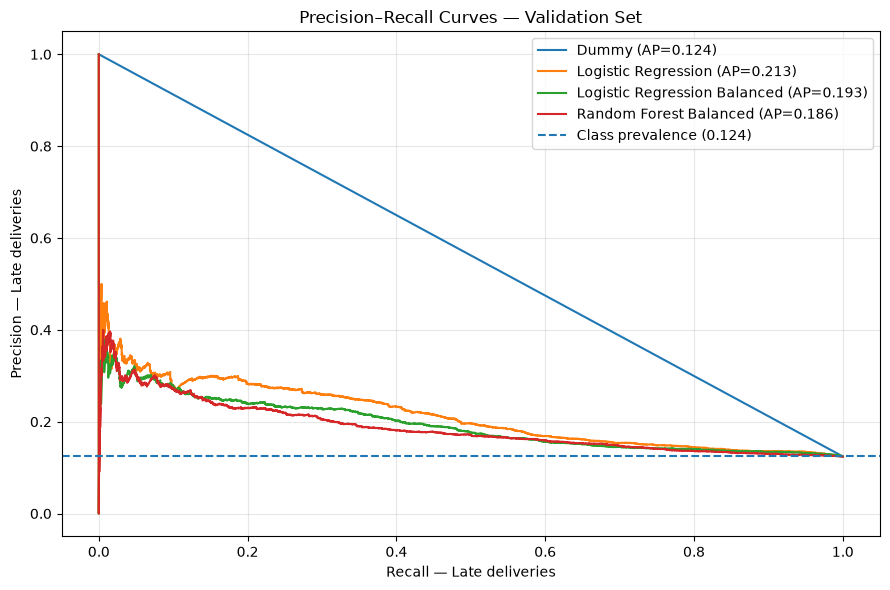

In [28]:

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(9, 6))

for name, y_prob in validation_probs.items():

    precision, recall, _ = precision_recall_curve(
        y_val, y_prob
    )

    ap = average_precision_score(y_val, y_prob)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

# Random ranking reference
baseline_ap = y_val.mean()

plt.axhline(
    baseline_ap,
    linestyle="--",
    label=f"Class prevalence ({baseline_ap:.3f})"
)

plt.xlabel("Recall — Late deliveries")
plt.ylabel("Precision — Late deliveries")
plt.title("Precision–Recall Curves — Validation Set")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:

probability_summary = pd.DataFrame({
    name: pd.Series(prob).describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
    for name, prob in validation_probs.items()
})

display(probability_summary.T.round(4))


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
Dummy,13327.0,0.0559,0.0000,0.0559,0.0559,0.0559,0.0559,0.0559,0.0559,0.0559,0.0559,0.0559
Logistic Regression,13327.0,0.0611,0.0491,0.0000,0.0215,0.0316,0.0467,0.0741,0.1182,0.1555,0.2538,0.6541
Logistic Regression Balanced,13327.0,0.4703,0.1717,0.0000,0.2612,0.3520,0.4585,0.5862,0.7048,0.7710,0.8723,0.9841
Random Forest Balanced,13327.0,0.2150,0.0793,0.0378,0.1140,0.1564,0.2099,0.2679,0.3208,0.3554,0.4169,0.6487


In [30]:

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []
best_thresholds = {}

for name, probabilities in validation_probs.items():

    if name == "Dummy":
        continue

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    # Final precision/recall element has no threshold
    p = precision[:-1]
    r = recall[:-1]

    f1_scores = np.divide(
        2 * p * r,
        p + r,
        out=np.zeros_like(p),
        where=(p + r) > 0
    )

    # Threshold maximizing validation F1
    best_idx = np.argmax(f1_scores)
    best_threshold = float(thresholds[best_idx])

    best_thresholds[name] = best_threshold

    # Compare default and optimized thresholds
    for strategy, threshold in [
        ("Default 0.5", 0.5),
        ("Max F1", best_threshold)
    ]:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": name,
            "Strategy": strategy,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        ["Model", "Strategy"]
    ).round(4)
)


,Model,Strategy,Threshold,Precision,Recall,F1,TP,FP,FN,TN
0,Logistic Regression,Default 0.5,0.5000,0.2500,0.0006,0.0012,1,3,1656,11667
1,Logistic Regression,Max F1,0.0849,0.2414,0.3808,0.2955,631,1983,1026,9687
2,Logistic Regression Balanced,Default 0.5,0.5000,0.1667,0.5468,0.2555,906,4530,751,7140
3,Logistic Regression Balanced,Max F1,0.6108,0.2153,0.3663,0.2712,607,2212,1050,9458
4,Random Forest Balanced,Default 0.5,0.5000,0.2000,0.0006,0.0012,1,4,1656,11666
5,Random Forest Balanced,Max F1,0.2402,0.1726,0.4973,0.2562,824,3951,833,7719


In [31]:

recall_target = 0.50
recall_constrained_results = []

for name, probabilities in validation_probs.items():

    if name == "Dummy":
        continue

    p, r, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    p, r = p[:-1], r[:-1]

    # Candidate thresholds meeting the recall target
    eligible = np.where(r >= recall_target)[0]

    if len(eligible) == 0:
        continue

    # Highest precision among eligible thresholds
    best_idx = eligible[np.argmax(p[eligible])]
    threshold = float(thresholds[best_idx])

    predictions = (probabilities >= threshold).astype(int)

    recall_constrained_results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Predicted Late": predictions.sum()
    })

recall_results_df = pd.DataFrame(recall_constrained_results)

display(
    recall_results_df.sort_values(
        "Precision", ascending=False
    ).round(4)
)


,Model,Threshold,Precision,Recall,F1,Predicted Late
0,Logistic Regression,0.0638,0.1968,0.5003,0.2825,4213
1,Logistic Regression Balanced,0.5261,0.1766,0.5015,0.2612,4706
2,Random Forest Balanced,0.2390,0.1712,0.5009,0.2552,4847


In [32]:

from xgboost import XGBClassifier

# Calculate class imbalance ratio from TRAIN ONLY
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

imbalance_ratio = negative_count / positive_count

print("Train imbalance ratio:", round(imbalance_ratio, 2))

base_params = {
    "n_estimators": 400,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "min_child_weight": 5,
    "reg_lambda": 3.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
}

xgb_models = {
    "XGBoost": XGBClassifier(
        **base_params,
        scale_pos_weight=1
    ),

    "XGBoost Moderate Weight": XGBClassifier(
        **base_params,
        scale_pos_weight=np.sqrt(imbalance_ratio)
    )
}

for name, model in xgb_models.items():
    print("Training:", name)
    model.fit(X_train_processed, y_train)
    print("Completed:", name)


Train imbalance ratio: 16.9
Training: XGBoost
Completed: XGBoost
Training: XGBoost Moderate Weight
Completed: XGBoost Moderate Weight


In [33]:

xgb_results = []

for name, model in xgb_models.items():

    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Store for comparison
    validation_probs[name] = y_prob

    precision, recall, thresholds = precision_recall_curve(
        y_val, y_prob
    )

    p = precision[:-1]
    r = recall[:-1]

    f1_scores = np.divide(
        2 * p * r,
        p + r,
        out=np.zeros_like(p),
        where=(p + r) > 0
    )

    best_idx = np.argmax(f1_scores)
    best_threshold = float(thresholds[best_idx])

    best_thresholds[name] = best_threshold

    y_pred = (
        y_prob >= best_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    xgb_results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, y_prob),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "Threshold": best_threshold,
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(4))


,Model,PR-AUC,ROC-AUC,Threshold,Precision,Recall,F1,TP,FP,FN,TN
0,XGBoost,0.1570,0.5746,0.0451,0.1496,0.6512,0.2433,1079,6134,578,5536
1,XGBoost Moderate Weight,0.1599,0.5797,0.1675,0.1525,0.6126,0.2443,1015,5639,642,6031


In [34]:

comparison_rows = []

all_models = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Logistic Regression Balanced": trained_models[
        "Logistic Regression Balanced"
    ],
    "Random Forest Balanced": trained_models[
        "Random Forest Balanced"
    ],
    **xgb_models
}

for name in all_models:
    y_prob = validation_probs[name]
    threshold = best_thresholds[name]

    y_pred = (y_prob >= threshold).astype(int)

    comparison_rows.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, y_prob),
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred)
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))


,Model,PR-AUC,Threshold,Precision,Recall,F1
0,Logistic Regression,0.2128,0.0849,0.2414,0.3808,0.2955
1,Logistic Regression Balanced,0.1927,0.6108,0.2153,0.3663,0.2712
2,Random Forest Balanced,0.1860,0.2402,0.1726,0.4973,0.2562
3,XGBoost Moderate Weight,0.1599,0.1675,0.1525,0.6126,0.2443
4,XGBoost,0.1570,0.0451,0.1496,0.6512,0.2433


In [35]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

feature_groups = {
    "Transaction": [
        "item_count", "n_sellers",
        "order_value", "freight_total",
        "avg_item_price", "freight_share",
        "is_multi_seller", "is_multi_item"
    ],
    "Product": [
        "n_products", "n_categories",
        "total_weight_g", "total_volume_cm3",
        "weight_observed_share", "volume_observed_share",
        "product_category_group"
    ],
    "Geographic": [
        "customer_state", "seller_state_group",
        "n_seller_states", "interstate_item_share"
    ],
    "Approval Timing": [
        "approval_hour", "approval_hour_sin",
        "approval_hour_cos", "approval_weekday",
        "approval_month", "approval_slot",
        "approval_delay_hours"
    ],
    "Promise": [
        "promised_days_from_approval"
    ]
}

def fit_and_evaluate(selected_features):
    num_cols = [
        c for c in selected_features
        if c in numerical_features
    ]
    cat_cols = [
        c for c in selected_features
        if c in categorical_features
    ]

    transformers = []

    if num_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            num_cols
        ))

    if cat_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            cat_cols
        ))

    pipeline = Pipeline([
        ("preprocess", ColumnTransformer(transformers)),
        ("model", LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])

    pipeline.fit(
        X_train[selected_features],
        y_train
    )

    probabilities = pipeline.predict_proba(
        X_val[selected_features]
    )[:, 1]

    return average_precision_score(y_val, probabilities)


ablation_results = []

# Full-feature reference
full_ap = fit_and_evaluate(feature_columns)

ablation_results.append({
    "Configuration": "All Features",
    "Feature Count": len(feature_columns),
    "PR-AUC": full_ap
})

# Remove each feature group independently
for group_name, group_cols in feature_groups.items():

    selected = [
        c for c in feature_columns
        if c not in group_cols
    ]

    ap = fit_and_evaluate(selected)

    ablation_results.append({
        "Configuration": f"Without {group_name}",
        "Feature Count": len(selected),
        "PR-AUC": ap
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df["Delta AP"] = (
    ablation_df["PR-AUC"] - full_ap
)

display(
    ablation_df.sort_values(
        "PR-AUC", ascending=False
    ).round(4)
)


,Configuration,Feature Count,PR-AUC,Delta AP
4,Without Approval Timing,20,0.2653,0.0525
2,Without Product,20,0.2178,0.0050
1,Without Transaction,19,0.2128,0.0000
0,All Features,27,0.2128,0.0000
5,Without Promise,26,0.1803,-0.0325
3,Without Geographic,23,0.1168,-0.0960


In [36]:

monthly_eval = pd.DataFrame({
    "approval_date": pd.to_datetime(
        model_df.loc[
            y_val.index, "order_approved_at"
        ].to_numpy()
    ),
    "actual": y_val.to_numpy(),
    "probability": validation_probs[
        "Logistic Regression"
    ]
})

monthly_eval["month"] = (
    monthly_eval["approval_date"]
    .dt.to_period("M")
)

monthly_results = []

for month, group in monthly_eval.groupby("month"):

    prevalence = group["actual"].mean()

    ap = average_precision_score(
        group["actual"],
        group["probability"]
    )

    monthly_results.append({
        "Month": str(month),
        "Orders": len(group),
        "Late Rate": prevalence,
        "PR-AUC": ap,
        "AP / Prevalence": (
            ap / prevalence if prevalence > 0 else np.nan
        )
    })

monthly_performance = pd.DataFrame(monthly_results)

display(monthly_performance.round(4))


,Month,Orders,Late Rate,PR-AUC,AP / Prevalence
0,2018-03,7081,0.1921,0.3459,1.8012
1,2018-04,6246,0.0476,0.1687,3.5471


In [37]:

# Remove all Approval Timing features
removed_features = feature_groups["Approval Timing"]

selected_features = [
    col for col in feature_columns
    if col not in removed_features
]

print("Selected features:", len(selected_features))
print("Removed features:", removed_features)

assert len(selected_features) == 20

# Separate feature types
selected_num = [
    col for col in selected_features
    if col in numerical_features
]

selected_cat = [
    col for col in selected_features
    if col in categorical_features
]

# Build a fresh preprocessing pipeline
preprocessor_reduced = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), selected_num),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), selected_cat)
])

# Train on training data only
reduced_model = Pipeline([
    ("preprocessor", preprocessor_reduced),
    ("classifier", LogisticRegression(
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

reduced_model.fit(
    X_train[selected_features],
    y_train
)

reduced_probs = reduced_model.predict_proba(
    X_val[selected_features]
)[:, 1]

print(
    "Reduced Model AP:",
    average_precision_score(y_val, reduced_probs)
)


Selected features: 20
Removed features: ['approval_hour', 'approval_hour_sin', 'approval_hour_cos', 'approval_weekday', 'approval_month', 'approval_slot', 'approval_delay_hours']
Reduced Model AP: 0.265280935359359


In [38]:

comparison_monthly = pd.DataFrame({
    "month": pd.to_datetime(
        model_df.loc[
            y_val.index, "order_approved_at"
        ]
    ).dt.to_period("M").astype(str).to_numpy(),

    "actual": y_val.to_numpy(),

    "full_model": validation_probs[
        "Logistic Regression"
    ],

    "reduced_model": reduced_probs
})

monthly_comparison = []

for month, group in comparison_monthly.groupby("month"):

    full_ap = average_precision_score(
        group["actual"],
        group["full_model"]
    )

    reduced_ap = average_precision_score(
        group["actual"],
        group["reduced_model"]
    )

    monthly_comparison.append({
        "Month": month,
        "Orders": len(group),
        "Late Rate": group["actual"].mean(),
        "Full AP": full_ap,
        "Reduced AP": reduced_ap,
        "Delta AP": reduced_ap - full_ap
    })

monthly_comparison_df = pd.DataFrame(
    monthly_comparison
)

display(monthly_comparison_df.round(4))


,Month,Orders,Late Rate,Full AP,Reduced AP,Delta AP
0,2018-03,7081,0.1921,0.3459,0.3442,-0.0018
1,2018-04,6246,0.0476,0.1687,0.1680,-0.0006


In [39]:

p, r, thresholds = precision_recall_curve(
    y_val, reduced_probs
)

f1_values = np.divide(
    2 * p[:-1] * r[:-1],
    p[:-1] + r[:-1],
    out=np.zeros_like(p[:-1]),
    where=(p[:-1] + r[:-1]) > 0
)

best_idx = np.argmax(f1_values)
reduced_threshold = float(thresholds[best_idx])

reduced_pred = (
    reduced_probs >= reduced_threshold
).astype(int)

print("Optimized threshold:", round(reduced_threshold, 4))

print("PR-AUC:", round(
    average_precision_score(y_val, reduced_probs), 4
))

print("Precision:", round(
    precision_score(y_val, reduced_pred), 4
))

print("Recall:", round(
    recall_score(y_val, reduced_pred), 4
))

print("F1:", round(
    f1_score(y_val, reduced_pred), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val, reduced_pred, labels=[0, 1]
))


Optimized threshold: 0.0884
PR-AUC: 0.2653
Precision: 0.3105
Recall: 0.414
F1: 0.3549

Confusion Matrix:
[[10147  1523]
 [  971   686]]


In [40]:

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

validation_analysis = pd.DataFrame({
    "month": pd.to_datetime(
        model_df.loc[y_val.index, "order_approved_at"]
    ).dt.to_period("M").astype(str).to_numpy(),

    "actual": y_val.to_numpy(),

    "full_score": validation_probs["Logistic Regression"],
    "reduced_score": reduced_probs
})

model_configs = {
    "Full Model": (
        "full_score",
        best_thresholds["Logistic Regression"]
    ),
    "Reduced Model": (
        "reduced_score",
        reduced_threshold
    )
}

monthly_diagnostics = []

for month, group in validation_analysis.groupby("month"):
    for model_name, (score_col, threshold) in model_configs.items():

        actual = group["actual"]
        scores = group[score_col]
        predictions = (scores >= threshold).astype(int)

        monthly_diagnostics.append({
            "Month": month,
            "Model": model_name,
            "Orders": len(group),
            "Late Rate": actual.mean(),
            "Mean Score": scores.mean(),
            "PR-AUC": average_precision_score(actual, scores),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            ),
            "Alert Rate": predictions.mean()
        })

monthly_diagnostics_df = pd.DataFrame(monthly_diagnostics)

display(monthly_diagnostics_df.round(4))


,Month,Model,Orders,Late Rate,Mean Score,PR-AUC,Precision,Recall,F1,Alert Rate
0,2018-03,Full Model,7081,0.1921,0.0522,0.3459,0.4172,0.3132,0.3578,0.1442
1,2018-03,Reduced Model,7081,0.1921,0.0619,0.3442,0.4064,0.3846,0.3952,0.1818
2,2018-04,Full Model,6246,0.0476,0.0713,0.1687,0.1287,0.6902,0.2169,0.2550
3,2018-04,Reduced Model,6246,0.0476,0.0557,0.1680,0.1768,0.5488,0.2674,0.1476


In [41]:

budget_results = []

actual = validation_analysis["actual"].to_numpy()
months = validation_analysis["month"].to_numpy()

for budget in [0.10, 0.20, 0.30]:

    k = round(len(actual) * budget)

    for model_name, (score_col, _) in model_configs.items():

        scores = validation_analysis[
            score_col
        ].to_numpy()

        # Select the top-K highest-risk orders
        top_indices = np.argsort(
            -scores, kind="stable"
        )[:k]

        true_positives = actual[top_indices].sum()

        budget_results.append({
            "Model": model_name,
            "Alert Budget": budget,
            "K": k,
            "TP": true_positives,
            "FP": k - true_positives,
            "Precision@K": true_positives / k,
            "Recall@K": true_positives / actual.sum(),
            "March Share": (
                months[top_indices] == "2018-03"
            ).mean()
        })

budget_df = pd.DataFrame(budget_results)

display(
    budget_df.sort_values(
        ["Alert Budget", "Precision@K"],
        ascending=[True, False]
    ).round(4)
)


,Model,Alert Budget,K,TP,FP,Precision@K,Recall@K,March Share
1,Reduced Model,0.1,1333,462,871,0.3466,0.2788,0.6039
0,Full Model,0.1,1333,369,964,0.2768,0.2227,0.3571
3,Reduced Model,0.2,2665,751,1914,0.2818,0.4532,0.5752
2,Full Model,0.2,2665,637,2028,0.2390,0.3844,0.3899
5,Reduced Model,0.3,3998,922,3076,0.2306,0.5564,0.5753
4,Full Model,0.3,3998,803,3195,0.2009,0.4846,0.3927


In [42]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# Two configurations to compare
feature_sets = {
    "Full Model": feature_columns,
    "Reduced Model": selected_features
}

def build_temporal_model(features):
    num_cols = [c for c in features if c in numerical_features]
    cat_cols = [c for c in features if c in categorical_features]

    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])


fold_months = [
    "2017-09-01",
    "2017-11-01",
    "2018-01-01",
    "2018-02-01"
]

approval_time = pd.to_datetime(
    model_df["order_approved_at"]
)

delivery_time = pd.to_datetime(
    model_df["order_delivered_customer_date"]
)

rolling_results = []

for fold_start in fold_months:
    val_start = pd.Timestamp(fold_start)
    val_end = val_start + pd.DateOffset(months=1)

    # Maintain a gap before validation
    train_end = val_start - pd.Timedelta(days=45)

    train_candidates = approval_time < train_end

    # Only labels observable at validation start
    train_mask = (
        train_candidates
        & delivery_time.notna()
        & (delivery_time < val_start)
    )

    val_mask = (
        (approval_time >= val_start)
        & (approval_time < val_end)
    )

    assert val_end <= pd.Timestamp("2018-03-01")
    assert (delivery_time.loc[train_mask] < val_start).all()
    assert not (train_mask & val_mask).any()

    y_fold = y.loc[val_mask]

    assert y.loc[train_mask].nunique() == 2
    assert y_fold.nunique() == 2

    for model_name, features in feature_sets.items():
        model = build_temporal_model(features)

        model.fit(
            X.loc[train_mask, features],
            y.loc[train_mask]
        )

        probabilities = model.predict_proba(
            X.loc[val_mask, features]
        )[:, 1]

        ap = average_precision_score(
            y_fold, probabilities
        )

        prevalence = y_fold.mean()

        rolling_results.append({
            "Month": fold_start[:7],
            "Model": model_name,
            "Train Orders": int(train_mask.sum()),
            "Pending Excluded": int(
                (train_candidates & ~train_mask).sum()
            ),
            "Validation Orders": int(val_mask.sum()),
            "Late Rate": prevalence,
            "PR-AUC": ap,
            "AP Lift": ap / prevalence,
            "ROC-AUC": roc_auc_score(
                y_fold, probabilities
            )
        })

rolling_df = pd.DataFrame(rolling_results)

display(rolling_df.round(4))


,Month,Model,Train Orders,Pending Excluded,Validation Orders,Late Rate,PR-AUC,AP Lift,ROC-AUC
0,2017-09,Full Model,16055,37,4156,0.0436,0.1136,2.6094,0.7105
1,2017-09,Reduced Model,16055,37,4156,0.0436,0.1177,2.7015,0.7137
2,2017-11,Full Model,24348,9,7149,0.1223,0.1680,1.3746,0.6210
3,2017-11,Reduced Model,24348,9,7149,0.1223,0.1684,1.3774,0.6236
4,2018-01,Full Model,33170,16,6990,0.0568,0.1009,1.7774,0.6355
5,2018-01,Reduced Model,33170,16,6990,0.0568,0.1009,1.7770,0.6346
6,2018-02,Full Model,41636,37,6501,0.1367,0.2936,2.1467,0.7036
7,2018-02,Reduced Model,41636,37,6501,0.1367,0.2934,2.1454,0.7028


In [43]:

rolling_comparison = rolling_df.pivot(
    index="Month",
    columns="Model",
    values="PR-AUC"
)

rolling_comparison["Delta AP"] = (
    rolling_comparison["Reduced Model"]
    - rolling_comparison["Full Model"]
)

display(rolling_comparison.round(4))

print("\nMean Delta AP:",
      round(rolling_comparison["Delta AP"].mean(), 4))

print("Median Delta AP:",
      round(rolling_comparison["Delta AP"].median(), 4))

print("Months Reduced Model wins:",
      (rolling_comparison["Delta AP"] > 0).sum(),
      "/", len(rolling_comparison))


Model,Full Model,Reduced Model,Delta AP
Month,,,
2017-09,0.1136,0.1177,0.0040
2017-11,0.1680,0.1684,0.0003
2018-01,0.1009,0.1009,-0.0000
2018-02,0.2936,0.2934,-0.0002



Mean Delta AP: 0.001
Median Delta AP: 0.0002
Months Reduced Model wins: 2 / 4


In [44]:
# Static mapping of Brazilian states to geographic regions
state_to_region = {
    "AC": "North", "AP": "North", "AM": "North",
    "PA": "North", "RO": "North", "RR": "North",
    "TO": "North",

    "AL": "Northeast", "BA": "Northeast",
    "CE": "Northeast", "MA": "Northeast",
    "PB": "Northeast", "PE": "Northeast",
    "PI": "Northeast", "RN": "Northeast",
    "SE": "Northeast",

    "DF": "Central-West", "GO": "Central-West",
    "MT": "Central-West", "MS": "Central-West",

    "ES": "Southeast", "MG": "Southeast",
    "RJ": "Southeast", "SP": "Southeast",

    "PR": "South", "RS": "South", "SC": "South"
}

geo_items = items[
    ["order_id", "seller_state", "customer_state"]
].copy()

# Verify that state codes are recognized
all_states = set(
    pd.concat([
        geo_items["seller_state"],
        geo_items["customer_state"]
    ]).dropna().unique()
)

unknown_states = all_states - set(state_to_region)

assert not unknown_states, (
    f"Unknown Brazilian state codes: {unknown_states}"
)

geo_items["seller_region"] = (
    geo_items["seller_state"].map(state_to_region)
)

geo_items["customer_region"] = (
    geo_items["customer_state"].map(state_to_region)
)

# Inter-region shipping, keeping missing routes unknown
valid = (
    geo_items["seller_region"].notna()
    & geo_items["customer_region"].notna()
)

geo_items["interregion_item"] = (
    geo_items["seller_region"]
    .ne(geo_items["customer_region"])
    .where(valid)
    .astype("Float64")
)

def unique_or_multiple(series):
    values = series.dropna().unique()

    if len(values) == 0:
        return "__UNKNOWN__"
    if len(values) == 1:
        return values[0]
    return "__MULTIPLE__"

geo_agg = (
    geo_items.groupby("order_id", as_index=False)
    .agg(
        seller_region_group=(
            "seller_region", unique_or_multiple
        ),
        n_seller_regions=(
            "seller_region", "nunique"
        ),
        interregion_item_share=(
            "interregion_item", "mean"
        )
    )
)

model_geo_df = model_df.merge(
    geo_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)

model_geo_df["customer_region"] = (
    model_geo_df["customer_state"]
    .map(state_to_region)
    .fillna("__UNKNOWN__")
)

# State route only when there is one known seller state
single_state = (
    model_geo_df["n_seller_states"].eq(1)
    & model_geo_df["seller_state_group"].isin(state_to_region)
    & model_geo_df["customer_state"].isin(state_to_region)
)

model_geo_df["state_route_pair"] = np.where(
    single_state,
    model_geo_df["seller_state_group"].astype(str)
    + "->"
    + model_geo_df["customer_state"].astype(str),
    "__MULTIPLE_OR_UNKNOWN__"
)

assert model_geo_df["order_id"].is_unique
assert len(model_geo_df) == len(model_df)

display(model_geo_df[[
    "customer_region",
    "seller_region_group",
    "n_seller_regions",
    "interregion_item_share",
    "state_route_pair"
]].head(10))

,customer_region,seller_region_group,n_seller_regions,interregion_item_share,state_route_pair
0,Southeast,Southeast,1,0.0,SP->RJ
1,Southeast,Southeast,1,0.0,SP->SP
2,Southeast,Southeast,1,0.0,MG->MG
3,Southeast,Southeast,1,0.0,SP->SP
4,Southeast,South,1,1.0,PR->SP
5,Southeast,Southeast,1,0.0,SP->MG
6,Southeast,Southeast,1,0.0,SP->SP
7,Southeast,Southeast,1,0.0,SP->SP
8,Southeast,Southeast,1,0.0,SP->SP
9,Southeast,Southeast,1,0.0,SP->SP


In [45]:
new_geo_numeric = [
    "n_seller_regions",
    "interregion_item_share"
]

new_geo_categorical = [
    "customer_region",
    "seller_region_group",
    "state_route_pair"
]

geo_numeric_features = (
    numerical_features + new_geo_numeric
)

geo_categorical_features = (
    categorical_features + new_geo_categorical
)

feature_sets_7a = {
    "Reduced": selected_features,

    "Geo-Region": (
        selected_features
        + new_geo_numeric
        + new_geo_categorical[:2]
    ),

    "Geo-Region-Route": (
        selected_features
        + new_geo_numeric
        + new_geo_categorical
    )
}

X_geo = model_geo_df[
    list(dict.fromkeys(
        col
        for features in feature_sets_7a.values()
        for col in features
    ))
].copy()

assert X_geo.index.equals(y.index)

for name, features in feature_sets_7a.items():
    print(name, len(features))

Reduced 20
Geo-Region 24
Geo-Region-Route 25


In [46]:
def build_geo_model(features):
    num_cols = [
        f for f in features
        if f in geo_numeric_features
    ]

    cat_cols = [
        f for f in features
        if f in geo_categorical_features
    ]

    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50
            ))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocess", preprocessing),
        ("model", LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])


geo_rolling_results = []

approval_time = pd.to_datetime(
    model_geo_df["order_approved_at"]
)

delivery_time = pd.to_datetime(
    model_geo_df["order_delivered_customer_date"]
)

for fold_start in fold_months:

    fold_val_start = pd.Timestamp(fold_start)
    fold_val_end = fold_val_start + pd.DateOffset(months=1)

    fold_train_cutoff = (
        fold_val_start - pd.Timedelta(days=45)
    )

    train_mask = (
        (approval_time < fold_train_cutoff)
        & delivery_time.notna()
        & (delivery_time < fold_val_start)
    )

    val_mask = (
        (approval_time >= fold_val_start)
        & (approval_time < fold_val_end)
    )

    for model_name, features in feature_sets_7a.items():

        model = build_geo_model(features)

        model.fit(
            X_geo.loc[train_mask, features],
            y.loc[train_mask]
        )

        probabilities = model.predict_proba(
            X_geo.loc[val_mask, features]
        )[:, 1]

        ap = average_precision_score(
            y.loc[val_mask], probabilities
        )

        prevalence = y.loc[val_mask].mean()

        geo_rolling_results.append({
            "Month": fold_start[:7],
            "Model": model_name,
            "PR-AUC": ap,
            "AP Lift": ap / prevalence
        })

geo_rolling_df = pd.DataFrame(geo_rolling_results)

geo_comparison = geo_rolling_df.pivot(
    index="Month",
    columns="Model",
    values="PR-AUC"
)

geo_comparison["Region Gain"] = (
    geo_comparison["Geo-Region"]
    - geo_comparison["Reduced"]
)

geo_comparison["Route Gain"] = (
    geo_comparison["Geo-Region-Route"]
    - geo_comparison["Reduced"]
)

display(geo_comparison.round(4))

print("\nAverage gains:")
print(
    geo_comparison[
        ["Region Gain", "Route Gain"]
    ].mean().round(4)
)

print("\nNumber of positive-gain months:")
print(
    (geo_comparison[
        ["Region Gain", "Route Gain"]
    ] > 0).sum()
)

Model,Geo-Region,Geo-Region-Route,Reduced,Region Gain,Route Gain
Month,,,,,
2017-09,0.1205,0.1177,0.1186,0.0018,-0.0009
2017-11,0.1699,0.1691,0.1692,0.0006,-0.0001
2018-01,0.1017,0.1033,0.1019,-0.0003,0.0014
2018-02,0.2933,0.2971,0.2951,-0.0018,0.0020



Average gains:
Model
Region Gain    0.0001
Route Gain     0.0006
dtype: float64

Number of positive-gain months:
Model
Region Gain    2
Route Gain     2
dtype: int64


In [47]:

# Create a new dataframe without modifying the baseline
model_promise_df = model_geo_df.copy()

promise_days = model_promise_df[
    "promised_days_from_approval"
]

estimated_date = pd.to_datetime(
    model_promise_df["order_estimated_delivery_date"]
)

# Fixed business-oriented buckets
model_promise_df["promise_window_bucket"] = pd.cut(
    promise_days,
    bins=[-np.inf, 0, 7, 14, 21, 30, 45, np.inf],
    labels=[
        "0_or_negative",
        "1-7",
        "8-14",
        "15-21",
        "22-30",
        "31-45",
        "46_plus"
    ]
).astype("object")

# Calendar characteristic of promised delivery
model_promise_df["estimated_delivery_weekday"] = (
    estimated_date.dt.day_name()
)

# Interaction between promise length and route
model_promise_df["promise_x_interstate"] = (
    model_promise_df["promised_days_from_approval"]
    * model_promise_df["interstate_item_share"]
)

display(model_promise_df[[
    "promised_days_from_approval",
    "promise_window_bucket",
    "estimated_delivery_weekday",
    "promise_x_interstate"
]].head(10))

print("\nPromise buckets:")
print(
    model_promise_df["promise_window_bucket"]
    .value_counts(dropna=False)
)


,promised_days_from_approval,promise_window_bucket,estimated_delivery_weekday,promise_x_interstate
0,16,15-21,Friday,16.0
1,19,15-21,Monday,0.0
2,22,22-30,Monday,0.0
3,12,8-14,Monday,0.0
4,41,31-45,Friday,41.0
5,20,15-21,Tuesday,20.0
6,25,22-30,Thursday,0.0
7,9,8-14,Thursday,0.0
8,21,15-21,Monday,0.0
9,16,15-21,Monday,0.0



Promise buckets:
promise_window_bucket
22-30            39215
15-21            24717
31-45            16505
8-14             11308
46_plus           1735
1-7               1594
0_or_negative        1
Name: count, dtype: int64


In [48]:

promise_num_features = list(dict.fromkeys(
    geo_numeric_features + ["promise_x_interstate"]
))

promise_cat_features = list(dict.fromkeys(
    geo_categorical_features + [
        "promise_window_bucket",
        "estimated_delivery_weekday"
    ]
))

feature_sets_7b = {
    "Reduced": selected_features,

    "Promise Shape": selected_features + [
        "promise_window_bucket",
        "estimated_delivery_weekday"
    ],

    "Promise + Route": selected_features + [
        "promise_window_bucket",
        "estimated_delivery_weekday",
        "promise_x_interstate"
    ]
}

def build_promise_model(features):
    num_cols = [
        c for c in features if c in promise_num_features
    ]
    cat_cols = [
        c for c in features if c in promise_cat_features
    ]

    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50
            ))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])


In [49]:

promise_results = []

approval_time = pd.to_datetime(
    model_promise_df["order_approved_at"]
)

delivery_time = pd.to_datetime(
    model_promise_df["order_delivered_customer_date"]
)

for fold_start in fold_months:
    val_start = pd.Timestamp(fold_start)
    val_end = val_start + pd.DateOffset(months=1)

    train_cutoff = val_start - pd.Timedelta(days=45)

    train_mask = (
        (approval_time < train_cutoff)
        & delivery_time.notna()
        & (delivery_time < val_start)
    )

    val_mask = (
        (approval_time >= val_start)
        & (approval_time < val_end)
    )

    assert not (train_mask & val_mask).any()
    assert (delivery_time.loc[train_mask] < val_start).all()

    for name, features in feature_sets_7b.items():
        model = build_promise_model(features)

        model.fit(
            model_promise_df.loc[train_mask, features],
            y.loc[train_mask]
        )

        probabilities = model.predict_proba(
            model_promise_df.loc[val_mask, features]
        )[:, 1]

        ap = average_precision_score(
            y.loc[val_mask], probabilities
        )

        promise_results.append({
            "Month": fold_start[:7],
            "Model": name,
            "PR-AUC": ap
        })

promise_rolling_df = pd.DataFrame(promise_results)

promise_comparison = promise_rolling_df.pivot(
    index="Month",
    columns="Model",
    values="PR-AUC"
)

for col in ["Promise Shape", "Promise + Route"]:
    promise_comparison[f"{col} Gain"] = (
        promise_comparison[col]
        - promise_comparison["Reduced"]
    )

display(promise_comparison.round(4))

print("\nMean gains:")
print(
    promise_comparison[
        ["Promise Shape Gain", "Promise + Route Gain"]
    ].mean().round(4)
)

print("\nPositive-gain months:")
print(
    (promise_comparison[
        ["Promise Shape Gain", "Promise + Route Gain"]
    ] > 0).sum()
)


Model,Promise + Route,Promise Shape,Reduced,Promise Shape Gain,Promise + Route Gain
Month,,,,,
2017-09,0.1038,0.1035,0.1186,-0.0151,-0.0148
2017-11,0.1670,0.1664,0.1692,-0.0028,-0.0022
2018-01,0.1051,0.1048,0.1019,0.0029,0.0031
2018-02,0.3027,0.3014,0.2951,0.0063,0.0076



Mean gains:
Model
Promise Shape Gain     -0.0022
Promise + Route Gain   -0.0016
dtype: float64

Positive-gain months:
Model
Promise Shape Gain      2
Promise + Route Gain    2
dtype: int64


In [50]:

# Build unique order-seller relationships
seller_orders = (
    items[["order_id", "seller_id"]]
    .dropna(subset=["seller_id"])
    .drop_duplicates()
    .merge(
        model_df[[
            "order_id",
            "order_approved_at",
            "order_delivered_customer_date",
            "is_late"
        ]],
        on="order_id",
        how="left",
        validate="many_to_one"
    )
)

seller_orders["order_approved_at"] = pd.to_datetime(
    seller_orders["order_approved_at"]
)

seller_orders["order_delivered_customer_date"] = pd.to_datetime(
    seller_orders["order_delivered_customer_date"]
)

# Historical events: completed deliveries only
# Exclude invalid sequences (delivery before approval)
seller_events = seller_orders.loc[
    seller_orders["order_delivered_customer_date"].notna()
    & (
        seller_orders["order_delivered_customer_date"]
        > seller_orders["order_approved_at"]
    )
].copy()

seller_events = seller_events.sort_values([
    "seller_id",
    "order_delivered_customer_date",
    "order_id"
])

# Cumulative completed orders and late deliveries
seller_events["historical_completed"] = (
    seller_events.groupby("seller_id").cumcount() + 1
)

seller_events["historical_late"] = (
    seller_events.groupby("seller_id")["is_late"].cumsum()
)

# Current orders to predict
queries = seller_orders[[
    "order_id",
    "seller_id",
    "order_approved_at"
]].rename(columns={
    "order_approved_at": "query_time"
})

queries = queries.sort_values(
    ["query_time", "seller_id"]
)

events = seller_events[[
    "seller_id",
    "order_delivered_customer_date",
    "historical_completed",
    "historical_late"
]].rename(columns={
    "order_delivered_customer_date": "event_time"
})

events = events.sort_values(
    ["event_time", "seller_id"]
)

# Match ONLY historical outcomes before each approval
seller_history = pd.merge_asof(
    queries,
    events,
    left_on="query_time",
    right_on="event_time",
    by="seller_id",
    direction="backward",
    allow_exact_matches=False
)

# Validate chronological availability
matched = seller_history["event_time"].notna()

assert (
    seller_history.loc[matched, "event_time"]
    < seller_history.loc[matched, "query_time"]
).all()

# Sellers without prior completed deliveries
seller_history["historical_completed"] = (
    seller_history["historical_completed"]
    .fillna(0)
)

seller_history["historical_late"] = (
    seller_history["historical_late"]
    .fillna(0)
)

seller_history["has_history"] = (
    seller_history["historical_completed"] > 0
).astype(int)

print("Order-seller relationships:", len(seller_history))
print("Relationships with prior history:",
      seller_history["has_history"].sum())

print("History coverage (%):",
      round(seller_history["has_history"].mean() * 100, 2))


Order-seller relationships: 96358
Relationships with prior history: 91191
History coverage (%): 94.64


In [51]:

seller_stats = (
    seller_history.groupby("order_id", as_index=False)
    .agg(
        prior_completed_orders=(
            "historical_completed", "sum"
        ),
        prior_late_orders=(
            "historical_late", "sum"
        ),
        sellers_with_history=(
            "has_history", "sum"
        ),
        seller_count=(
            "seller_id", "size"
        )
    )
)

# Smoothing with a fixed prior of 5%
# Avoids extreme estimates for small histories
seller_stats["seller_prior_late_rate"] = (
    (seller_stats["prior_late_orders"] + 1)
    / (seller_stats["prior_completed_orders"] + 20)
)

seller_stats["seller_prior_count_log"] = np.log1p(
    seller_stats["prior_completed_orders"]
)

seller_stats["seller_history_coverage"] = (
    seller_stats["sellers_with_history"]
    / seller_stats["seller_count"]
)

new_seller_features = [
    "seller_prior_late_rate",
    "seller_prior_count_log",
    "seller_history_coverage"
]

model_seller_df = model_df.merge(
    seller_stats[["order_id"] + new_seller_features],
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(model_seller_df) == len(model_df)
assert model_seller_df["order_id"].is_unique

print("Missing seller history features:")
print(model_seller_df[new_seller_features].isna().sum())

print("\nFeature statistics:")
display(model_seller_df[new_seller_features].describe())

print("\nSample features:")
display(model_seller_df[
    ["order_id"] + new_seller_features + ["is_late"]
].head(10))


Missing seller history features:
seller_prior_late_rate     0
seller_prior_count_log     0
seller_history_coverage    0
dtype: int64

Feature statistics:


,seller_prior_late_rate,seller_prior_count_log,seller_history_coverage
count,95075.000000,95075.000000,95075.0
mean,0.048677,3.834481,0.946371
std,0.030255,1.857577,0.224564
min,0.004405,0.000000,0.0
25%,0.030303,2.564949,1.0
50%,0.042904,3.970292,1.0
75%,0.056604,5.220356,1.0
max,0.348485,7.850493,1.0



Sample features:


,order_id,seller_prior_late_rate,seller_prior_count_log,seller_history_coverage,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,0.021277,4.317488,1.0,0
1,00018f77f2f0320c557190d7a144bdd3,0.050000,0.000000,0.0,0
2,000229ec398224ef6ca0657da4fc703e,0.041667,1.609438,1.0,0
3,00024acbcdf0a6daa1e931b038114c75,0.066667,2.397895,1.0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,0.045455,1.098612,1.0,0
5,00048cc3ae777c65dbb7d2a0634bc1ea,0.050000,0.000000,0.0,0
6,00054e8431b9d7675808bcb819fb4a32,0.037975,4.094345,1.0,0
7,0005a1a1728c9d785b8e2b08b904576c,0.084615,4.709530,1.0,0
8,0005f50442cb953dcd1d21e1fb923495,0.116883,4.060443,1.0,0
9,00061f2a7bc09da83e415a52dc8a4af1,0.040903,7.243513,1.0,0


In [52]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# Feature configurations
feature_sets_7c = {
    "Reduced": selected_features,
    "Reduced + Seller History": (
        selected_features + new_seller_features
    )
}

seller_numerical_features = (
    numerical_features + new_seller_features
)

def build_seller_model(features):
    num_cols = [
        c for c in features
        if c in seller_numerical_features
    ]

    cat_cols = [
        c for c in features
        if c in categorical_features
    ]

    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50
            ))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessing),
        ("model", LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])


# Chronological information
approval_time = pd.to_datetime(
    model_seller_df["order_approved_at"]
)

delivery_time = pd.to_datetime(
    model_seller_df["order_delivered_customer_date"]
)

assert model_seller_df.index.equals(y.index)

seller_rolling_results = []

for fold_start in fold_months:

    val_start = pd.Timestamp(fold_start)
    val_end = val_start + pd.DateOffset(months=1)

    train_cutoff = val_start - pd.Timedelta(days=45)

    train_mask = (
        (approval_time < train_cutoff)
        & delivery_time.notna()
        & (delivery_time < val_start)
    )

    val_mask = (
        (approval_time >= val_start)
        & (approval_time < val_end)
    )

    assert not (train_mask & val_mask).any()
    assert (delivery_time.loc[train_mask] < val_start).all()

    for name, features in feature_sets_7c.items():

        model = build_seller_model(features)

        model.fit(
            model_seller_df.loc[train_mask, features],
            y.loc[train_mask]
        )

        probabilities = model.predict_proba(
            model_seller_df.loc[val_mask, features]
        )[:, 1]

        ap = average_precision_score(
            y.loc[val_mask],
            probabilities
        )

        prevalence = y.loc[val_mask].mean()

        seller_rolling_results.append({
            "Month": fold_start[:7],
            "Model": name,
            "Train Orders": int(train_mask.sum()),
            "Val Orders": int(val_mask.sum()),
            "Late Rate": prevalence,
            "PR-AUC": ap,
            "AP Lift": ap / prevalence,
            "ROC-AUC": roc_auc_score(
                y.loc[val_mask], probabilities
            )
        })

seller_rolling_df = pd.DataFrame(
    seller_rolling_results
)

display(seller_rolling_df.round(4))


,Month,Model,Train Orders,Val Orders,Late Rate,PR-AUC,AP Lift,ROC-AUC
0,2017-09,Reduced,16055,4156,0.0436,0.1186,2.7244,0.7138
1,2017-09,Reduced + Seller History,16055,4156,0.0436,0.1119,2.5697,0.7084
2,2017-11,Reduced,24348,7149,0.1223,0.1692,1.3842,0.6235
3,2017-11,Reduced + Seller History,24348,7149,0.1223,0.1676,1.3713,0.6214
4,2018-01,Reduced,33170,6990,0.0568,0.1019,1.7949,0.6337
5,2018-01,Reduced + Seller History,33170,6990,0.0568,0.1029,1.8124,0.6417
6,2018-02,Reduced,41636,6501,0.1367,0.2951,2.1581,0.7032
7,2018-02,Reduced + Seller History,41636,6501,0.1367,0.2823,2.0643,0.6982


In [53]:

seller_comparison = seller_rolling_df.pivot(
    index="Month",
    columns="Model",
    values="PR-AUC"
)

seller_comparison["Seller History Gain"] = (
    seller_comparison["Reduced + Seller History"]
    - seller_comparison["Reduced"]
)

display(seller_comparison.round(4))

gains = seller_comparison["Seller History Gain"]

print("\nMean Delta AP:", round(gains.mean(), 4))
print("Median Delta AP:", round(gains.median(), 4))
print("Positive-gain months:",
      (gains > 0).sum(), "/", len(gains))

print("\nMean AP by model:")
display(
    seller_rolling_df.groupby("Model")["PR-AUC"]
    .mean()
    .sort_values(ascending=False)
)


Model,Reduced,Reduced + Seller History,Seller History Gain
Month,,,
2017-09,0.1186,0.1119,-0.0067
2017-11,0.1692,0.1676,-0.0016
2018-01,0.1019,0.1029,0.0010
2018-02,0.2951,0.2823,-0.0128



Mean Delta AP: -0.005
Median Delta AP: -0.0042
Positive-gain months: 1 / 4

Mean AP by model:


Model
Reduced                     0.171231
Reduced + Seller History    0.166198
Name: PR-AUC, dtype: float64

In [54]:

from sklearn.base import clone

final_cutoff = pd.Timestamp("2018-07-01")
test_end = pd.Timestamp("2018-09-01")

approval = pd.to_datetime(
    model_df["order_approved_at"]
)

delivered = pd.to_datetime(
    model_df["order_delivered_customer_date"]
)

# Only historical orders with known outcomes
final_train_mask = (
    (approval < final_cutoff)
    & delivered.notna()
    & (delivered < final_cutoff)
)

# Unseen future orders
final_test_mask = (
    (approval >= final_cutoff)
    & (approval < test_end)
)

assert not (final_train_mask & final_test_mask).any()
assert len(X.loc[final_test_mask]) == 11868

print("Final train orders:", final_train_mask.sum())
print("Final test orders:", final_test_mask.sum())

print("Final train late rate:",
      y.loc[final_train_mask].mean())

print("Final test late rate:",
      y.loc[final_test_mask].mean())


Final train orders: 81570
Final test orders: 11868
Final train late rate: 0.07144783621429447
Final test late rate: 0.04996629592180654


In [55]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Freeze threshold selected from Validation
final_threshold = reduced_threshold

# Fresh copy of the selected 20-feature pipeline
final_model = clone(reduced_model)

final_model.fit(
    X.loc[final_train_mask, selected_features],
    y.loc[final_train_mask]
)

# Final test predictions
test_probabilities = final_model.predict_proba(
    X.loc[final_test_mask, selected_features]
)[:, 1]

test_actual = y.loc[final_test_mask]

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

final_results = pd.DataFrame([{
    "PR-AUC": average_precision_score(
        test_actual, test_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        test_actual, test_probabilities
    ),
    "Precision": precision_score(
        test_actual, test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        test_actual, test_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        test_actual, test_predictions,
        zero_division=0
    ),
    "Accuracy": accuracy_score(
        test_actual, test_predictions
    ),
    "Threshold": final_threshold
}])

display(final_results.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    test_actual,
    test_predictions,
    labels=[0, 1]
))


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
0,0.087,0.6347,0.0708,0.747,0.1294,0.4976,0.0884



Confusion Matrix:
[[5462 5813]
 [ 150  443]]


In [56]:

test_budget_results = []

actual = test_actual.to_numpy()
scores = test_probabilities

for budget in [0.10, 0.20, 0.30]:
    k = round(len(actual) * budget)

    top_idx = np.argsort(-scores, kind="stable")[:k]

    tp = int(actual[top_idx].sum())

    test_budget_results.append({
        "Alert Budget": budget,
        "Orders Flagged": k,
        "True Positives": tp,
        "False Positives": k - tp,
        "Precision@K": tp / k,
        "Recall@K": tp / actual.sum()
    })

display(
    pd.DataFrame(test_budget_results).round(4)
)


,Alert Budget,Orders Flagged,True Positives,False Positives,Precision@K,Recall@K
0,0.1,1187,108,1079,0.0910,0.1821
1,0.2,2374,163,2211,0.0687,0.2749
2,0.3,3560,247,3313,0.0694,0.4165


In [57]:

# Descriptive diagnostics on the locked Test set
test_diagnostics = pd.DataFrame({
    "month": pd.to_datetime(
        model_df.loc[
            final_test_mask, "order_approved_at"
        ]
    ).dt.to_period("M").astype(str).to_numpy(),

    "actual": test_actual.to_numpy(),
    "score": test_probabilities,
    "predicted": test_predictions
})

monthly_test_results = []

for month, group in test_diagnostics.groupby("month"):
    actual = group["actual"]
    scores = group["score"]
    predicted = group["predicted"]

    monthly_test_results.append({
        "Month": month,
        "Orders": len(group),
        "Late Rate": actual.mean(),
        "Mean Score": scores.mean(),
        "PR-AUC": average_precision_score(
            actual, scores
        ),
        "AP Lift": (
            average_precision_score(actual, scores)
            / actual.mean()
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "Alert Rate": predicted.mean()
    })

monthly_test_df = pd.DataFrame(monthly_test_results)

display(monthly_test_df.round(4))

print("Test Confusion Matrix:")
print(confusion_matrix(
    test_actual, test_predictions, labels=[0, 1]
))


,Month,Orders,Late Rate,Mean Score,PR-AUC,AP Lift,Precision,Recall,F1,Alert Rate
0,2018-07,5483,0.0343,0.1041,0.1125,3.2814,0.0516,0.6489,0.0956,0.4310
1,2018-08,6385,0.0634,0.1244,0.0828,1.3056,0.0825,0.7926,0.1494,0.6097


Test Confusion Matrix:
[[5462 5813]
 [ 150  443]]


In [58]:

import numpy as np
import pandas as pd

# Freeze threshold chosen before testing
threshold = reduced_threshold

# Original model predicts the same test orders
old_test_probs = reduced_model.predict_proba(
    X.loc[final_test_mask, selected_features]
)[:, 1]

# Already computed from the refitted model
new_test_probs = test_probabilities

def summarize_scores(name, scores, actual):
    scores = np.asarray(scores)

    return {
        "Scenario": name,
        "Actual Late Rate": np.mean(actual),
        "Mean Score": scores.mean(),
        "Median Score": np.median(scores),
        "P90 Score": np.quantile(scores, 0.90),
        "P95 Score": np.quantile(scores, 0.95),
        "Predicted Late Rate": np.mean(
            scores >= threshold
        ),
        "Predicted Late Count": int(
            (scores >= threshold).sum()
        )
    }

diagnostic_results = pd.DataFrame([
    summarize_scores(
        "Original Model - Validation",
        reduced_probs,
        y_val
    ),
    summarize_scores(
        "Original Model - Test",
        old_test_probs,
        test_actual
    ),
    summarize_scores(
        "Refitted Model - Test",
        new_test_probs,
        test_actual
    )
])

display(diagnostic_results.round(4))

print("Original Train Late Rate:",
      round(y_train.mean(), 4))

print("Final Refit Train Late Rate:",
      round(y.loc[final_train_mask].mean(), 4))


,Scenario,Actual Late Rate,Mean Score,Median Score,P90 Score,P95 Score,Predicted Late Rate,Predicted Late Count
0,Original Model - Validation,0.1243,0.0590,0.0468,0.1136,0.1444,0.1658,2209
1,Original Model - Test,0.0500,0.0763,0.0636,0.1423,0.1804,0.2721,3229
2,Refitted Model - Test,0.0500,0.1151,0.0927,0.2337,0.2891,0.5271,6256


Original Train Late Rate: 0.0559
Final Refit Train Late Rate: 0.0714


In [59]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score
)

diagnostics = []

for name, probs in {
    "Original Model": old_test_probs,
    "Refitted Model": test_probabilities
}.items():

    predictions = (probs >= reduced_threshold).astype(int)

    diagnostics.append({
        "Model": name,
        "PR-AUC": average_precision_score(
            test_actual, probs
        ),
        "ROC-AUC": roc_auc_score(
            test_actual, probs
        ),
        "Brier Score": brier_score_loss(
            test_actual, probs
        ),
        "Mean Score": probs.mean(),
        "Alert Rate": predictions.mean(),
        "Precision": precision_score(
            test_actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            test_actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            test_actual, predictions, zero_division=0
        )
    })

model_diagnostics_df = pd.DataFrame(diagnostics)

display(model_diagnostics_df.round(4))


,Model,PR-AUC,ROC-AUC,Brier Score,Mean Score,Alert Rate,Precision,Recall,F1
0,Original Model,0.0777,0.6362,0.0489,0.0763,0.2721,0.0728,0.3963,0.1230
1,Refitted Model,0.0870,0.6347,0.0553,0.1151,0.5271,0.0708,0.7470,0.1294
